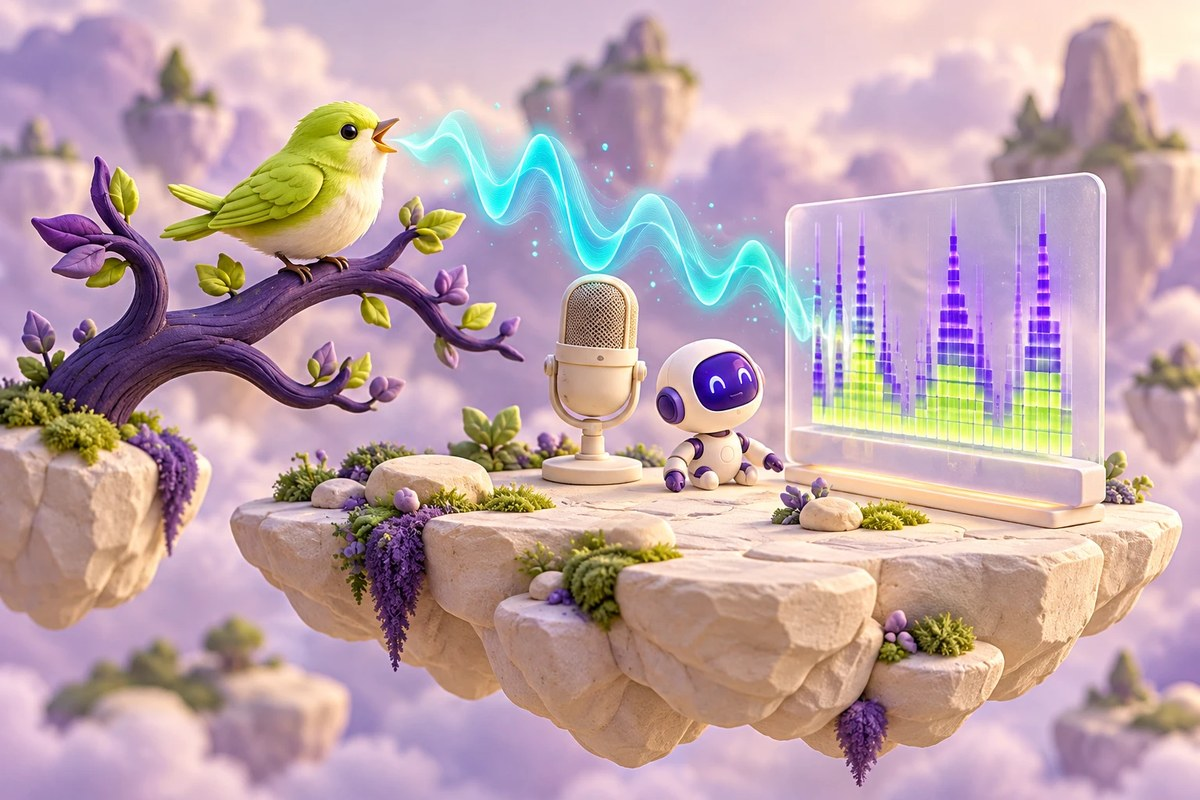

AI PATH · Аудио и сигналы · Урок 001

# Пение птиц: от записи к классификации

Аудиоокна, шесть семейств признаков и сравнение Dense с Conv1D

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-001-goal"></a>
## Что вы разберёте

Проследить путь от файла пения до вероятностей 88 классов и научиться замечать утечку между обучением и проверкой.

### Перед началом

- Массивы NumPy и их размерности
- Частота дискретизации и спектр
- Обучающая и проверочная выборки

### Что понадобится

- Colab с доступом к Google Drive
- Архив «база пения птиц. 88 классов.zip» по пути из ячейки 4
- birdsong_metadata.csv и каталог songs/songs из архива
- Librosa 0.7.0, NumPy, Pandas, Matplotlib, scikit-learn и совместимые TensorFlow/Keras

## Навигация по уроку

- [Цель и подготовка](#ai-001-goal)
- [Карта урока](#ai-001-map)
- [Подготовить аудиолабораторию](#ai-001-section-01)
- [Связать запись с видом птицы](#ai-001-section-02)
- [Разобрать звук на признаки](#ai-001-section-03)
- [Проверить масштабы и разделение](#ai-001-section-04)
- [Собрать многовходовую Dense-сеть](#ai-001-section-05)
- [Добавить свёртку по времени](#ai-001-section-06)
- [Прочитать предсказание](#ai-001-section-07)
- [Проверить путь нового аудио](#ai-001-section-08)
- [Проверьте понимание](#ai-001-practice)
- [Источники и ограничения](#ai-001-provenance)

<a id="ai-001-map"></a>
## Карта урока

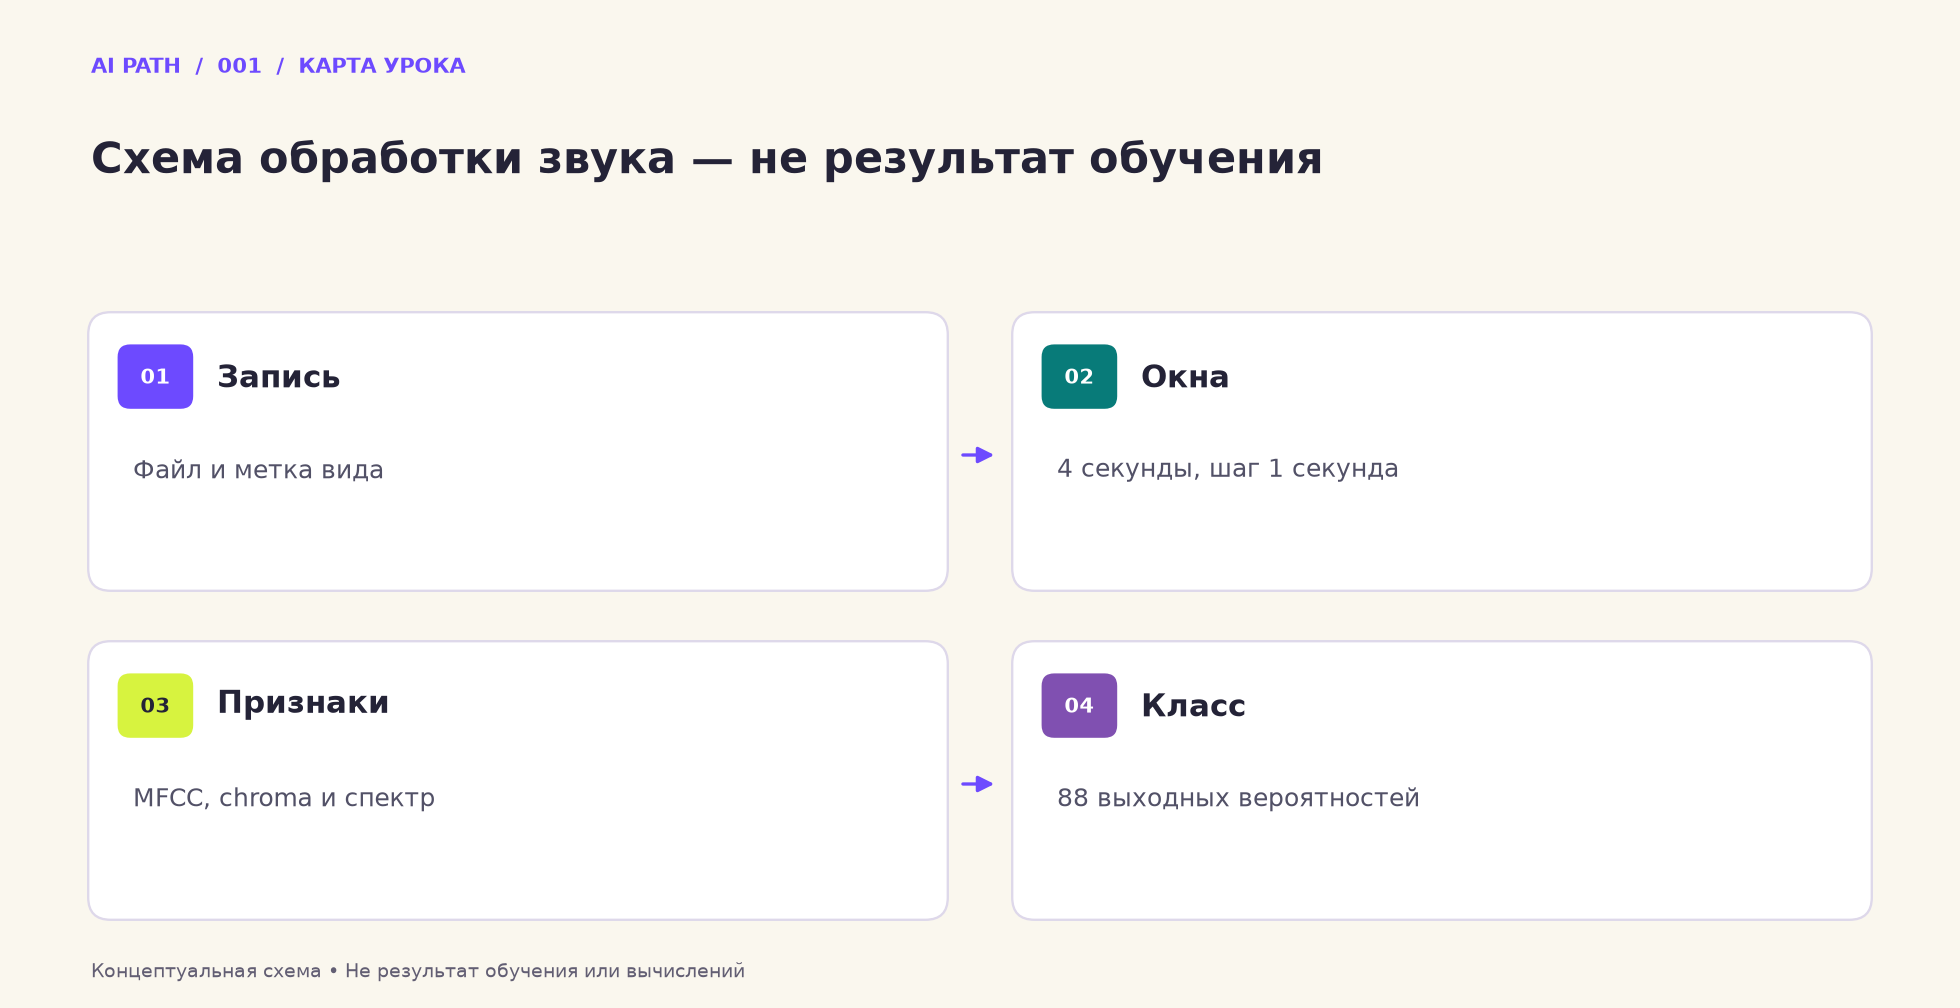

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Запись** — Файл и метка вида
2. **Окна** — 4 секунды, шаг 1 секунда
3. **Признаки** — MFCC, chroma и спектр
4. **Класс** — 88 выходных вероятностей

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2%22%D0%90%D1%83%D0%B4%D0%B8%D0%BE_%D0%A0%D0%B0%D1%81%D0%BF%D0%BE%D0%B7%D0%BD%D0%B0%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5_%D0%BF%D1%82%D0%B8%D1%86_%D0%BF%D0%BE_%D0%BF%D0%B5%D0%BD%D0%B8%D1%8E_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a id="ai-001-section-01"></a>
## 01 · Подготовить аудиолабораторию

Сначала проверьте версии библиотек и наличие архива. Исходник смешивает импорты Keras и TensorFlow, поэтому запуск зависит от окружения.

_Далее — исходные ячейки учебного материала._

In [1]:
# Устанавливаем пакет librosa для работы с аудио
!pip install librosa==0.7.0

     |████████████████████████████████| 1.6MB 6.1MB/s 
  Created wheel for librosa: filename=librosa-0.7.0-cp36-none-any.whl size=1598345 sha256=550932edbb185b31e04f74de7d35d4a28defd36f8d97cc9d715306d4b478d8d7
  Stored in directory: /root/.cache/pip/wheels/49/1d/38/c8ad12fcad67569d8e730c3275be5e581bd589558484a0f881
Successfully built librosa
  Found existing installation: librosa 0.6.3
    Uninstalling librosa-0.6.3:
      Successfully uninstalled librosa-0.6.3


In [2]:
# Подключаем библиотеки
import sklearn
from IPython.display import Audio  # Воспроизведение аудиофайлов
import time                        # Для подсчёта времени 
import zipfile                     # Для разорхивации базы
import pandas as pd                # Для работы с табличными данными
from tensorflow.keras import utils # Для to_categorical
from google.colab import files     # Загрузка файлов
import os                          # Работа с папками и файлами
import librosa                     # Параметризация аудио
import librosa.feature             # Инструменты для параметризации
import numpy as np                 # Numpy массивы
import matplotlib.pyplot as plt    # Отображение графиков

# Отрисовка графиков в ячейках collab
%matplotlib inline 
from keras.optimizers import Adam, RMSprop # Оптимизатор для задания шага обучения
from keras.models import Sequential, Model # Два формата модели keras
from keras.layers import concatenate, Input, Dense, Dropout, BatchNormalization, Flatten, Conv1D, Conv2D, MaxPooling1D, Reshape, Lambda # Базовые слови
from sklearn.model_selection import train_test_split # Разбиение на обучающую и проверочную выборку
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler # Для нормировки данных
from keras.objectives import binary_crossentropy # Импортируем функцию потерь
from keras.layers.advanced_activations import LeakyReLU # Импортируем функцию активации отдельным слоем
from keras import backend as K # Устанавливаем переменную для окружения кераса


In [3]:
# Подключаем Google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Разархивируем архив с базой
bi = zipfile.ZipFile('/content/drive/My Drive/Базы/база пения птиц. 88 классов.zip', 'r')
bi.extractall()

<a id="ai-001-section-02"></a>
## 02 · Связать запись с видом птицы

Таблица связывает file_id с english_cname. До извлечения признаков убедитесь, что каждый выбранный файл имеет одну ожидаемую метку.

_Далее — исходные ячейки учебного материала._

In [5]:
# Подгружаем данные нашей базы
data = pd.read_csv('birdsong_metadata.csv')

In [6]:
# Выведем данные
data.head(10)

,file_id,genus,species,english_cname,who_provided_recording,country,latitude,longitute,type,license
0,132608,Acanthis,flammea,Common Redpoll,Jarek Matusiak,Poland,50.7932,15.4995,"female, male, song",http://creativecommons.org/licenses/by-nc-sa/3.0/
1,132611,Acanthis,flammea,Common Redpoll,Jarek Matusiak,Poland,50.7932,15.4995,"flight call, male, song",http://creativecommons.org/licenses/by-nc-sa/3.0/
2,35068,Acanthis,flammea,Common Redpoll,Sander Bot,Netherlands,52.8176,6.4326,"call, song",http://creativecommons.org/licenses/by-nc-nd/2.5/
3,82715,Acrocephalus,palustris,Marsh Warbler,Dougie Preston,United Kingdom,60.3539,-1.2689,Song,http://creativecommons.org/licenses/by-nc-nd/2.5/
4,64685,Acrocephalus,palustris,Marsh Warbler,Dougie Preston,United Kingdom,60.3539,-1.2689,Song,http://creativecommons.org/licenses/by-nc-nd/2.5/
5,64686,Acrocephalus,palustris,Marsh Warbler,Dougie Preston,United Kingdom,60.3539,-1.2689,Song,http://creativecommons.org/licenses/by-nc-nd/2.5/
6,120664,Acrocephalus,schoenobaenus,Sedge Warbler,david m,United Kingdom,56.5860,-6.1855,"male, song",http://creativecommons.org/licenses/by-nc-nd/3.0/
7,120666,Acrocephalus,schoenobaenus,Sedge Warbler,david m,United Kingdom,56.5860,-6.1855,"male, song",http://creativecommons.org/licenses/by-nc-nd/3.0/
8,76767,Acrocephalus,schoenobaenus,Sedge Warbler,Richard Dunn,United Kingdom,55.2809,-1.5801,song,http://creativecommons.org/licenses/by-nc-nd/2.5/
9,124052,Acrocephalus,scirpaceus,Eurasian Reed Warbler,david m,United Kingdom,51.8985,-0.5372,"call, female, male, song",http://creativecommons.org/licenses/by-nc-nd/3.0/


In [7]:
# Посмотрим количество уникальных ID
data['file_id'].nunique()

264

In [8]:
# Выведем все названия птиц(колонка english_cname)
data.english_cname.unique()
bb = data.english_cname.unique()
bb

array(['Common Redpoll', 'Marsh Warbler', 'Sedge Warbler',
       'Eurasian Reed Warbler', 'Long-tailed Tit', 'Eurasian Skylark',
       'Meadow Pipit', 'Tree Pipit', 'Common Swift', 'Canada Goose',
       'Dunlin', 'European Nightjar', 'European Goldfinch',
       'Eurasian Treecreeper', 'European Greenfinch', 'Black-headed Gull',
       'Western Jackdaw', 'Rock Dove', 'Stock Dove', 'Common Wood Pigeon',
       'Northern Raven', 'Carrion Crow', 'Rook', 'Common Cuckoo',
       'Eurasian Blue Tit', 'Common House Martin',
       'Great Spotted Woodpecker', 'Black Woodpecker', 'Corn Bunting',
       'Yellowhammer', 'Common Reed Bunting', 'European Robin',
       'Common Chaffinch', 'Eurasian Coot', 'Common Snipe',
       'Common Moorhen', 'Eurasian Jay', 'Red-throated Loon',
       'Eurasian Oystercatcher', 'Barn Swallow', 'Eurasian Wryneck',
       'Willow Ptarmigan', 'European Herring Gull', 'Common Linnet',
       'River Warbler', 'Red Crossbill', 'Common Nightingale',
       'European

In [9]:
# Создадим список названий птиц в соответствии с тем порядком, в котором они подгружаются
v=[]
for l in os.listdir(f'/content/songs/songs/'):
  songname = f'{l}'
  list(songname)
  a = int(songname[2:-5]) # Чтобы достать из названия файла только id
  for i in range(len(data['file_id'].values)):
    if a==data['file_id'].values[i]:
      v.append(i) # Составляем список id в том порядке, в котором загружаются файлы

birds1=[]
for j in v:
  birds1.append(data['english_cname'][j])

print(birds1)
print(len(birds1))

['Eurasian Tree Sparrow', 'Eurasian Bullfinch', 'Common Redshank', 'European Green Woodpecker', 'Meadow Pipit', 'Common Whitethroat', 'Common Snipe', 'Coal Tit', 'European Turtle Dove', 'European Bee-eater', 'European Nightjar', 'Eurasian Blackcap', 'Common Redshank', 'European Greenfinch', 'Grey Partridge', 'Tree Pipit', 'Western Yellow Wagtail', 'Common Moorhen', 'Dunnock', 'Common Redshank', 'Rook', 'Lesser Whitethroat', 'Eurasian Collared Dove', 'Tree Pipit', 'Long-tailed Tit', 'Stock Dove', 'Common Starling', 'Spotted Flycatcher', 'Eurasian Coot', 'Western Jackdaw', 'Great Spotted Woodpecker', 'European Goldfinch', 'Common Whitethroat', 'Eurasian Blue Tit', 'Yellowhammer', 'Eurasian Treecreeper', 'Black Woodpecker', 'Wood Sandpiper', 'Common Linnet', 'Eurasian Magpie', 'Common Redstart', 'Northern Lapwing', 'Eurasian Reed Warbler', 'Common Cuckoo', 'Garden Warbler', 'Common House Martin', 'Carrion Crow', 'Willow Warbler', 'Dunlin', 'Eurasian Skylark', 'Common Blackbird', 'Eurasian

In [10]:
# Прослушаем пример записи
Audio(filename='/content/songs/songs/xc132611.flac')

<a id="ai-001-section-03"></a>
## 03 · Разобрать звук на признаки

Четырёхсекундные окна с шагом в секунду превращаются в chroma, MFCC, центроид, ширину спектра, rolloff и ZCR. Соседние окна содержат общий звук.

_Далее — исходные ячейки учебного материала._

In [11]:

def get_features(y, sr):

  '''
    get_features - функция параметризации данных
     y - временной ряд аудио
     sr - sampling rate(по умолчанию 22050) - частота дискретизации
  '''
  # Двумерные
  chroma_stft = librosa.feature.chroma_stft(y=y, sr=sr) # Частота цветности
  mfcc = librosa.feature.mfcc(y=y, sr=sr)               # Мел кепстральные коэффициенты

  # Одномерные
  spec_cent = librosa.feature.spectral_centroid(y=y, sr=sr) # Спектральный центроид
  spec_bw = librosa.feature.spectral_bandwidth(y=y, sr=sr)  # Ширина полосы частот
  rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)    # Спектральный спад частоты
  zcr = librosa.feature.zero_crossing_rate(y)               # Пересечения нуля

  # Возвращаем получившийся список
  return chroma_stft, mfcc, spec_cent, spec_bw, rolloff, zcr

In [12]:
# Создаём пустые листы
X_train_1 = []
X_train_2 = []
X_train_3 = []
X_train_4 = []
X_train_5 = []
X_train_6 = []
Y_train = []

# Запоминаем время старта формирования выборки
curr_time = time.time()

i = 0
# Проходим по файлам папки
for filename in os.listdir(f'/content/songs/songs/'):
  songname = f'/content/songs/songs/{filename}'
  
  # Выделим из имени песни только число
  songnum = f'{filename}'
  list(songnum)
  a = int(songnum[2:-5])
  
# Следующая часть кода предназначена для того, чтобы присвоить каждой записи
# нужный цикл, а так как у нас по 3 записи каждой птицы и они загружаются
# вразноброс, мы делаем некую фильтрацию 264 записей по 88 классам(в соответствии
# с данными таблицы .csv)
#########################################################################

  # Пройдемся по всем значениям столбца 'file_id' и обнаружим текущую песню
  for k in range(len(data['file_id'])):

    # Ищем строку в данных соответствующую текущей записи
    if a == data['file_id'][k]:

      # Вытаскиваем значение названия птицы для текущей записи
      w = data['english_cname'][k]

      # Проходимся циклом по нашим классам(88) и присваиваем в соответствии с записью
      for t in range(len(bb)):
        if w == bb[t]:
#########################################################################

          # Загружаем в y аудиосигнал
          y, sr = librosa.load(songname, mono=True)

          # Превращаем сигнал в параметризованные данные и раскусываем по 4 секунды, с шагом в 1 секунду
          for p in range(0, (int(len(y)//22050))-4):
            
            chroma_stft, mfcc, spec_cent, spec_bw, rolloff, zcr = get_features(y[p*sr:(p+4)*sr], sr)

            # Добавляем строку в X_train
            X_train_1.append(chroma_stft)
            X_train_2.append(mfcc)
            X_train_3.append(spec_cent)
            X_train_4.append(spec_bw)
            X_train_5.append(rolloff)
            X_train_6.append(zcr)

            # Добавляем в Y_train номер классов в формате ohe
            Y_train.append(utils.to_categorical(t, len(bb)))

  # Выводим информацию о готовности обработки базы
  print(i, " Птица ", birds1[i], " готова -> ", round(time.time() - curr_time), "c", sep="")
  i+=1
  curr_time = time.time()

# Превращаем обучающую выборку в numpy массивы
X_train_1 = np.array(X_train_1)
X_train_2 = np.array(X_train_2)
X_train_3 = np.array(X_train_3)
X_train_4 = np.array(X_train_4)
X_train_5 = np.array(X_train_5)
X_train_6 = np.array(X_train_6)
Y_train = np.array(Y_train)

0 Птица Eurasian Tree Sparrow готова -> 12c
1 Птица Eurasian Bullfinch готова -> 6c
2 Птица Common Redshank готова -> 2c
3 Птица European Green Woodpecker готова -> 2c


/usr/local/lib/python3.6/dist-packages/librosa/core/pitch.py:146: UserWarning: Trying to estimate tuning from empty frequency set.
  warnings.warn('Trying to estimate tuning from empty frequency set.')


4 Птица Meadow Pipit готова -> 9c
5 Птица Common Whitethroat готова -> 6c
6 Птица Common Snipe готова -> 3c
7 Птица Coal Tit готова -> 2c
8 Птица European Turtle Dove готова -> 6c
9 Птица European Bee-eater готова -> 5c
10 Птица European Nightjar готова -> 5c
11 Птица Eurasian Blackcap готова -> 2c
12 Птица Common Redshank готова -> 1c
13 Птица European Greenfinch готова -> 3c
14 Птица Grey Partridge готова -> 1c
15 Птица Tree Pipit готова -> 5c
16 Птица Western Yellow Wagtail готова -> 4c
17 Птица Common Moorhen готова -> 8c
18 Птица Dunnock готова -> 1c
19 Птица Common Redshank готова -> 6c
20 Птица Rook готова -> 3c
21 Птица Lesser Whitethroat готова -> 3c
22 Птица Eurasian Collared Dove готова -> 7c
23 Птица Tree Pipit готова -> 5c
24 Птица Long-tailed Tit готова -> 3c
25 Птица Stock Dove готова -> 11c
26 Птица Common Starling готова -> 18c
27 Птица Spotted Flycatcher готова -> 3c
28 Птица Eurasian Coot готова -> 3c
29 Птица Western Jackdaw готова -> 7c
30 Птица Great Spotted Woodp

In [13]:
# Создаём backup обучающей выборки
X_train_backup_1 = X_train_1.copy()
X_train_backup_2 = X_train_2.copy()
X_train_backup_3 = X_train_3.copy()
X_train_backup_4 = X_train_4.copy()
X_train_backup_5 = X_train_5.copy()
X_train_backup_6 = X_train_6.copy()
Y_train_backup = Y_train.copy()

In [14]:
X_train_1 = X_train_backup_1.copy()
X_train_2 = X_train_backup_2.copy()
X_train_3 = X_train_backup_3.copy()
X_train_4 = X_train_backup_4.copy()
X_train_5 = X_train_backup_5.copy()
X_train_6 = X_train_backup_6.copy()
Y_train = Y_train_backup.copy()

In [15]:
# Проверяем размерность Y_train
Y_train.shape

(16540, 88)

In [16]:
y_train_class = np.argmax(Y_train, axis=1)
print(len(y_train_class))

16540


In [17]:
# Выводим размеры обучающей выборки
print(X_train_1.shape)
print(X_train_2.shape)
print(X_train_3.shape)
print(X_train_4.shape)
print(X_train_5.shape)
print(X_train_6.shape)
print(Y_train.shape)
print(y_train_class.shape)

(16540, 12, 173)
(16540, 20, 173)
(16540, 1, 173)
(16540, 1, 173)
(16540, 1, 173)
(16540, 1, 173)
(16540, 88)
(16540,)


<a id="ai-001-section-04"></a>
## 04 · Проверить масштабы и разделение

В исходнике нормализация предшествует случайному разделению окон. Разберите, почему проверку надёжнее отделять по исходным записям, а параметры масштаба получать только на обучении.

_Далее — исходные ячейки учебного материала._

In [18]:
# Делаем reshape одномерных данных
X_train_3 = X_train_3.reshape(X_train_3.shape[0], X_train_3.shape[2], X_train_3.shape[1])
X_train_4 = X_train_4.reshape(X_train_4.shape[0], X_train_4.shape[2], X_train_4.shape[1])
X_train_5 = X_train_5.reshape(X_train_5.shape[0], X_train_5.shape[2], X_train_5.shape[1])
X_train_6 = X_train_6.reshape(X_train_6.shape[0], X_train_6.shape[2], X_train_6.shape[1])
print(X_train_1.shape)
print(X_train_2.shape)
print(X_train_3.shape)
print(X_train_4.shape)
print(X_train_5.shape)
print(X_train_6.shape)
print(Y_train.shape)
print(y_train_class.shape)

(16540, 12, 173)
(16540, 20, 173)
(16540, 173, 1)
(16540, 173, 1)
(16540, 173, 1)
(16540, 173, 1)
(16540, 88)
(16540,)


In [19]:
def scale(X):
  '''
     scale() - функция для нормализации данных
     X - данные, которые нужно нормальзивать

  '''
  global min_X # делаем переменные глобальными, чтобы использовать при предсказании тестового файла
  global max_X
  min_X = X.min()
  max_X = X.max()
  
  X = (X - min_X) / (max_X - min_X)

  return X

In [20]:
# Нормализуем тренировочные данные
X_train_1_scaled = scale(X_train_1)

Xmin1 = min_X # Запоминаем значения, чтобы потом использовать для предикта
Xmax1 = max_X # Запоминаем значения, чтобы потом использовать для предикта

X_train_2_scaled = scale(X_train_2)

Xmin2 = min_X # Запоминаем значения, чтобы потом использовать для предикта
Xmax2 = max_X # Запоминаем значения, чтобы потом использовать для предикта

X_train_3_scaled = scale(X_train_3)

X_train_4_scaled = scale(X_train_4)
X_train_5_scaled = scale(X_train_5)
X_train_6_scaled = scale(X_train_6)

In [21]:
np.random.sample(2)

array([0.79862911, 0.21917363])

In [22]:
# Разделяем на тренировочную, проверочную и тестовую выборки
mask = np.random.sample(16540)

# Создание обучающей выборки
train_mask = mask < 0.8 

# Создание проверочной выборки
val_mask = (mask >= 0.8) & (mask < 0.999)

# Создание тестовой выборки
test_mask = (mask >= 0.999)

print(len(X_train_1_scaled[train_mask]))
print(len(X_train_1_scaled[val_mask]))
print(len(X_train_1_scaled[test_mask]))

13244
3284
12


<a id="ai-001-section-05"></a>
## 05 · Собрать многовходовую Dense-сеть

Сравните вариант с двумя входами и вариант с шестью. У каждого входа своя форма, а выход остаётся распределением по 88 классам.

_Далее — исходные ячейки учебного материала._

## Простая сеть из двух параметризованных данных(частота цветности и мелкепстральные  коэффициенты) со слоями Dense, Dropout, BatchNormalization

Epoch 1/20
265/265 [==============================] - 1s 5ms/step - loss: 3.0747 - accuracy: 0.3044 - val_loss: 4.3534 - val_accuracy: 0.1297
Epoch 2/20
265/265 [==============================] - 1s 4ms/step - loss: 1.8284 - accuracy: 0.5502 - val_loss: 1.5432 - val_accuracy: 0.6547
Epoch 3/20
265/265 [==============================] - 1s 4ms/step - loss: 1.3517 - accuracy: 0.6540 - val_loss: 1.0029 - val_accuracy: 0.7640
Epoch 4/20
265/265 [==============================] - 1s 4ms/step - loss: 1.0732 - accuracy: 0.7190 - val_loss: 0.8034 - val_accuracy: 0.7932
Epoch 5/20
265/265 [==============================] - 1s 4ms/step - loss: 0.8905 - accuracy: 0.7588 - val_loss: 0.6647 - val_accuracy: 0.8270
Epoch 6/20
265/265 [==============================] - 1s 4ms/step - loss: 0.7682 - accuracy: 0.7892 - val_loss: 0.5095 - val_accuracy: 0.8724
Epoch 7/20
265/265 [==============================] - 1s 4ms/step - loss: 0.6823 - accuracy: 0.8086 - val_loss: 0.4319 - val_accuracy: 0.8886
Epoch 

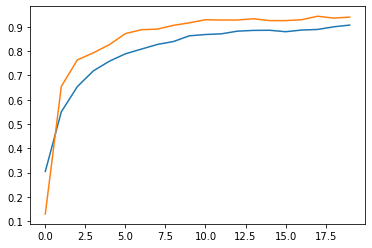

In [23]:
# Создадим инпуты соответствующих данных
input_1 = Input((12, 173))
input_2 = Input((20, 173))

# Блок 1 "Частота цветности"
x1 = BatchNormalization()(input_1)
x1 = Flatten()(x1)

# Блок 2 "Мелкепстральные коэффициенты"
x2 = BatchNormalization()(input_2)
x2 = Flatten()(x2)

# Соединяем данные всех блоков
x = concatenate([x1, x2])

# В последнем слое 88 нейронов(по количеству классов)
x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)
x = BatchNormalization()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
x = BatchNormalization()(x)
x = Dense(88, activation='softmax')(x)

model_simple = Model([input_1, input_2], x)

model_simple.compile(optimizer=Adam(lr=1e-3),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model_simple.fit([X_train_1_scaled[train_mask], X_train_2_scaled[train_mask]],
                    Y_train[train_mask],
                    epochs=20,
                    batch_size=50,
                    validation_data=([X_train_1_scaled[val_mask], X_train_2_scaled[val_mask]],
                    Y_train[val_mask]))

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.show()

## Сеть из 6 параметризованных данных(частота цветности, мелкепстральные коэффициенты, спектральный центроид, ширина полосы частот, спектральный спад частоты, пересечение 0) 

Epoch 1/10
265/265 [==============================] - 2s 6ms/step - loss: 2.0865 - accuracy: 0.5146 - val_loss: 4.8499 - val_accuracy: 0.1605
Epoch 2/10
265/265 [==============================] - 1s 5ms/step - loss: 0.6562 - accuracy: 0.8337 - val_loss: 0.9221 - val_accuracy: 0.7500
Epoch 3/10
265/265 [==============================] - 1s 5ms/step - loss: 0.2805 - accuracy: 0.9316 - val_loss: 0.5857 - val_accuracy: 0.8316
Epoch 4/10
265/265 [==============================] - 1s 5ms/step - loss: 0.1352 - accuracy: 0.9692 - val_loss: 0.5223 - val_accuracy: 0.8429
Epoch 5/10
265/265 [==============================] - 1s 5ms/step - loss: 0.0842 - accuracy: 0.9814 - val_loss: 0.4523 - val_accuracy: 0.8730
Epoch 6/10
265/265 [==============================] - 1s 5ms/step - loss: 0.0387 - accuracy: 0.9931 - val_loss: 0.4276 - val_accuracy: 0.8791
Epoch 7/10
265/265 [==============================] - 1s 5ms/step - loss: 0.0167 - accuracy: 0.9983 - val_loss: 0.3803 - val_accuracy: 0.8934
Epoch 

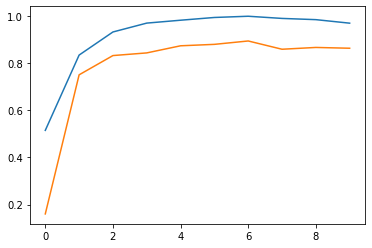

In [24]:
# Создадим инпуты соответствующих данных
input_1 = Input((12, 173))
input_2 = Input((20, 173))
input_3 = Input((173, 1))
input_4 = Input((173, 1))
input_5 = Input((173, 1))
input_6 = Input((173, 1))

# Блок 1 "частота цветности"
x1 = BatchNormalization()(input_1)
x1 = Flatten()(x1)

# Блок 2 "Мелкепстральные коэффициенты"
x2 = BatchNormalization()(input_2)
x2 = Flatten()(x2)

# Блок 3
x3 = BatchNormalization()(input_3)
x3 = Flatten()(x3)

# Блок 4 "спектральный центроид"
x4 = BatchNormalization()(input_4)
x4 = Flatten()(x4)

# Блок 5 "ширина полосы частот"
x5 = BatchNormalization()(input_5)
x5 = Flatten()(x5)

# Блок 6 "спектральный спад частоты"
x6 = BatchNormalization()(input_6)
x6 = Flatten()(x6)

# Соединяем данные всех блоков
x = concatenate([x1, x2, x3, x4, x5, x6])

# В последнем слое 88 нейронов(по количеству классов)
x = Dense(100, activation='elu')(x)
x = Dense(88, activation='softmax')(x)

model_dense = Model([input_1, input_2, input_3, input_4, input_5, input_6], x)

model_dense.compile(optimizer=Adam(lr=1e-3),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model_dense.fit([X_train_1_scaled[train_mask], X_train_2_scaled[train_mask], X_train_3_scaled[train_mask], X_train_4_scaled[train_mask], X_train_5_scaled[train_mask], X_train_6_scaled[train_mask]],
                    Y_train[train_mask],
                    epochs=10,
                    batch_size=50,
                    validation_data=([X_train_1_scaled[val_mask], X_train_2_scaled[val_mask], X_train_3_scaled[val_mask], X_train_4_scaled[val_mask], X_train_5_scaled[val_mask], X_train_6_scaled[val_mask]],
                    Y_train[val_mask]))

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.show()

<a id="ai-001-section-06"></a>
## 06 · Добавить свёртку по времени

Conv1D обрабатывает последовательности признаков перед объединением ветвей. Сравнивайте модели на одном разделении, а не по случайно выбранным удачным эпохам.

_Далее — исходные ячейки учебного материала._

## Conv1D + MaxPooling + BatchNormalization

Epoch 1/10
265/265 [==============================] - 10s 38ms/step - loss: 1.8146 - accuracy: 0.5637 - val_loss: 4.6910 - val_accuracy: 0.1985
Epoch 2/10
265/265 [==============================] - 9s 34ms/step - loss: 0.3842 - accuracy: 0.8966 - val_loss: 0.3298 - val_accuracy: 0.9062
Epoch 3/10
265/265 [==============================] - 9s 34ms/step - loss: 0.1912 - accuracy: 0.9439 - val_loss: 0.2362 - val_accuracy: 0.9318
Epoch 4/10
265/265 [==============================] - 9s 34ms/step - loss: 0.1602 - accuracy: 0.9539 - val_loss: 0.1615 - val_accuracy: 0.9543
Epoch 5/10
265/265 [==============================] - 9s 34ms/step - loss: 0.1118 - accuracy: 0.9664 - val_loss: 0.2459 - val_accuracy: 0.9364
Epoch 6/10
265/265 [==============================] - 9s 34ms/step - loss: 0.4232 - accuracy: 0.9046 - val_loss: 0.5844 - val_accuracy: 0.8736
Epoch 7/10
265/265 [==============================] - 9s 34ms/step - loss: 0.2306 - accuracy: 0.9438 - val_loss: 0.1152 - val_accuracy: 0.971

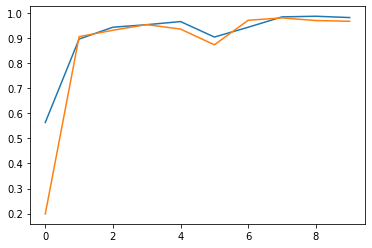

In [25]:
# Создадим инпуты соответствующих данных
input_1 = Input((12, 173))
input_2 = Input((20, 173))
input_3 = Input((173, 1))
input_4 = Input((173, 1))
input_5 = Input((173, 1))
input_6 = Input((173, 1))


# Блок 1 "частота цветности"
x1 = BatchNormalization()(input_1)
x1 = Conv1D(256, 3, padding="same", activation="elu")(x1)
x1 = Conv1D(256, 3, padding="same", activation="elu")(x1)
x1 = MaxPooling1D(2)(x1)
x1 = Conv1D(128, 3, padding="same", activation="elu")(x1)
x1 = Conv1D(128, 3, padding="same", activation="elu")(x1)
x1 = MaxPooling1D(2)(x1)
x1 = Conv1D(64, 3, padding="same", activation="elu")(x1)
x1 = Conv1D(64, 3, padding="same", activation="elu")(x1)
x1 = Flatten()(x1)

# Блок 2 "Мелкепстральные коэффициенты"
x2 = BatchNormalization()(input_2)
x2 = Conv1D(256, 3, padding="same", activation="elu")(x2)
x2 = Conv1D(256, 3, padding="same", activation="elu")(x2)
x2 = MaxPooling1D(2)(x2)
x2 = Conv1D(128, 3, padding="same", activation="elu")(x2)
x2 = Conv1D(128, 3, padding="same", activation="elu")(x2)
x2 = MaxPooling1D(2)(x2)
x2 = Conv1D(64, 3, padding="same", activation="elu")(x2)
x2 = Conv1D(64, 3, padding="same", activation="elu")(x2)
x2 = Flatten()(x2)

# Блок 3
x3 = BatchNormalization()(input_3)
x3 = Conv1D(256, 3, padding="same", activation="elu")(x3)
x3 = Conv1D(256, 3, padding="same", activation="elu")(x3)
x3 = MaxPooling1D(2)(x3)
x3 = Conv1D(128, 3, padding="same", activation="elu")(x3)
x3 = Conv1D(128, 3, padding="same", activation="elu")(x3)
x3 = MaxPooling1D(2)(x3)
x3 = Conv1D(64, 3, padding="same", activation="elu")(x3)
x3 = Conv1D(64, 3, padding="same", activation="elu")(x3)
x3 = Flatten()(x3)

# Блок 4 "спектральный центроид"
x4 = BatchNormalization()(input_4)
x4 = Conv1D(256, 3, padding="same", activation="elu")(x4)
x4 = Conv1D(256, 3, padding="same", activation="elu")(x4)
x4 = MaxPooling1D(2)(x4)
x4 = Conv1D(128, 3, padding="same", activation="elu")(x4)
x4 = Conv1D(128, 3, padding="same", activation="elu")(x4)
x4 = MaxPooling1D(2)(x4)
x4 = Conv1D(64, 3, padding="same", activation="elu")(x4)
x4 = Conv1D(64, 3, padding="same", activation="elu")(x4)
x4 = Flatten()(x4)

# Блок 5 "ширина полосы частот"
x5 = BatchNormalization()(input_5)
x5 = Conv1D(256, 3, padding="same", activation="elu")(x5)
x5 = Conv1D(256, 3, padding="same", activation="elu")(x5)
x5 = MaxPooling1D(2)(x5)
x5 = Conv1D(128, 3, padding="same", activation="elu")(x5)
x5 = Conv1D(128, 3, padding="same", activation="elu")(x5)
x5 = MaxPooling1D(2)(x5)
x5 = Conv1D(64, 3, padding="same", activation="elu")(x5)
x5 = Conv1D(64, 3, padding="same", activation="elu")(x5)
x5 = Flatten()(x5)

# Блок 6 "спектральный спад частоты"
x6 = BatchNormalization()(input_6)
x6 = Conv1D(256, 3, padding="same", activation="elu")(x6)
x6 = Conv1D(256, 3, padding="same", activation="elu")(x6)
x6 = MaxPooling1D(2)(x6)
x6 = Conv1D(128, 3, padding="same", activation="elu")(x6)
x6 = Conv1D(128, 3, padding="same", activation="elu")(x6)
x6 = MaxPooling1D(2)(x6)
x6 = Conv1D(64, 3, padding="same", activation="elu")(x6)
x6 = Conv1D(64, 3, padding="same", activation="elu")(x6)
x6 = Flatten()(x6)


# Соединяем данные всех блоков
x = concatenate([x1, x2, x3, x4, x5, x6])

# В последнем слое 88 нейронов(по количеству классов)
x = Dense(100, activation='elu')(x)
x = Dense(100, activation='elu')(x)
x = Dense(88, activation='softmax')(x)

model = Model([input_1, input_2, input_3, input_4, input_5, input_6], x)

model.compile(optimizer=Adam(lr=1e-3),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit([X_train_1_scaled[train_mask], X_train_2_scaled[train_mask], X_train_3_scaled[train_mask], X_train_4_scaled[train_mask], X_train_5_scaled[train_mask], X_train_6_scaled[train_mask]],
                    Y_train[train_mask],
                    epochs=10,
                    batch_size=50,
                    validation_data=([X_train_1_scaled[val_mask], X_train_2_scaled[val_mask], X_train_3_scaled[val_mask], X_train_4_scaled[val_mask], X_train_5_scaled[val_mask], X_train_6_scaled[val_mask]],
                    Y_train[val_mask]))

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.show()

<a id="ai-001-section-07"></a>
## 07 · Прочитать предсказание

В блоке проверки вызывается model_simple. Убедитесь, что проверяете именно ту модель, которую собираетесь обсуждать.

_Далее — исходные ячейки учебного материала._

# Предсказание тестовой выборки

In [26]:
# Делаем предикт тестовой выборки
y = model_simple.predict([X_train_1_scaled[test_mask],X_train_2_scaled[test_mask]])

In [27]:
# Выводим выход с softmax
# И распознанный класс
print(np.argmax(y, axis=1))
# Проверяем правильный индекс списка с
print(np.argmax(Y_train[test_mask], axis=1))

[47 80 73 40  2 22 62 42 43 33 61 45]
[47 80 73 40  2 22 62 42 43 33 61 45]


<a id="ai-001-section-08"></a>
## 08 · Проверить путь нового аудио

После загрузки файла путь songname снова указывает на файл из songs/songs. Сверьте фактически обработанный файл с тем, который прослушали.

_Далее — исходные ячейки учебного материала._

# Предсказание аудио из интернета

In [ ]:
# Загружаем свой файл для проверки
files.upload()

In [ ]:
# Послушаем запись
Audio(filename='/content/AV7734_Oriolus+oriolus_BE_1_0-75_C.flac')

In [ ]:
# Выбираем песню для распознавания
songname = '/content/songs/songs/xc102048.flac'
# Получаем аудио сигнал
y, sr = librosa.load(songname, mono=True)

X1 = []
X2 = []


# Параметризуем сигнал
for p in range(0, (int(len(y)//22050))-4):
  chroma_stft, mfcc, spec_cent, spec_bw, rolloff, zcr = get_features(y[p*sr:(p+4)*sr], sr)



  # Добавляем строку в X_train
  X1.append(chroma_stft)
  X2.append(mfcc)

# Превращаем в numpy массив
X1 = np.array(X1)
X2 = np.array(X2)

In [ ]:
print(X1.shape)
print(X2.shape)

(20, 12, 173)
(20, 20, 173)


In [ ]:
# Делаем скейлинг на основании тех Xmin и Xmax, которые были на тренировочнфх данных
X1scaled = (X1 - Xmin1) / (Xmax1 - Xmin1)
X2scaled = (X2 - Xmin2) / (Xmax2 - Xmin2)


In [ ]:
# Делаем предикт
y = model_simple.predict([X1scaled,X2scaled])

In [ ]:
# Выводим выход с softmax
# И распознанный класс
print(y.shape)
print(np.argmax(y, axis=1))


(20, 88)
[30 30 30 30 30 30 30 30 30 30 61 30 30 30 30 30 61 30 30 30]


In [ ]:
# Проверим какую птицу предсказала сеть
bb[30]

'Common Reed Bunting'

In [ ]:
data[data['file_id']==102048]

,file_id,genus,species,english_cname,who_provided_recording,country,latitude,longitute,type,license
90,102048,Emberiza,schoeniclus,Common Reed Bunting,Richard Dunn,United Kingdom,55.07,-1.6059,song,http://creativecommons.org/licenses/by-nc-nd/2.5/


<a id="ai-001-practice"></a>
## Проверьте понимание

1. Проверьте соответствие file_id, имени файла и метки вида.
2. Найдите окна одной записи, которые могут попасть в разные части выборки.
3. Проверьте, какой объект модели и какой аудиофайл реально использует последний блок.

### Один самостоятельный эксперимент

В отдельной копии сначала разделите записи целиком, затем сравните модель с двумя и шестью входами на одном разделении.

**Критерий успеха:** Исходные записи не пересекаются между частями; параметры нормализации получены на обучении; различия моделей описаны без обещания заданной точности.

<a id="ai-001-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/AudioNet/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2%22%D0%90%D1%83%D0%B4%D0%B8%D0%BE_%D0%A0%D0%B0%D1%81%D0%BF%D0%BE%D0%B7%D0%BD%D0%B0%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5_%D0%BF%D1%82%D0%B8%D1%86_%D0%BF%D0%BE_%D0%BF%D0%B5%D0%BD%D0%B8%D1%8E_ipynb%22.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Архив на Drive и аудиофайлы не включены в этот ноутбук; доступность не проверялась.
- Librosa 0.7.0 и смешанные старые API Keras требуют отдельного согласования версий.
- Нормализация всей выборки и случайное разделение перекрывающихся окон создают утечку; маска длиной 16540 жёстко задана, тестовая доля очень мала.
- Последний блок использует файл из учебного каталога вместо автоматически выбранного загруженного файла; сохранённые метрики не подтверждают новый независимый запуск.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.